# 04 · Retrieval evaluation and ablation (1 GPU)
Every variant on the same test set, the same frozen teacher index and the same top-100 retrieval. No training here.

Metrics: Recall@{1,5,10,20,50,100}, MRR@10, nDCG@10. Precision@K isn't reported: with ~1 positive per query,
P@100 ≤ 0.01, so recall@100 carries the same ranking information.

Input: `01` (data + teacher vectors), `02` + `03` (checkpoints), `03`'s `metrics.json` (all rows so far).

In [1]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")


In [2]:
# setup: clone/pull the repo on Kaggle, put it on sys.path, install what's missing (re-run to pull latest code)
import os, sys, importlib.util
REPO_URL = "https://github.com/pyther-hub/hlm-poc.git"
ON_KAGGLE = os.path.exists("/kaggle/working")
REPO = "/kaggle/working/hlm-poc" if ON_KAGGLE else os.path.abspath("..")
if ON_KAGGLE:
    if not os.path.exists(REPO):
        !git clone -q {REPO_URL} {REPO}
    else:
        !git -C {REPO} pull -q
sys.path.insert(0, REPO)

# HF token (higher rate limits, faster downloads). Kaggle: Add-ons -> Secrets -> add "HF_TOKEN", attach to notebook.
# Spawned workers inherit os.environ. Locally: export HF_TOKEN or `huggingface-cli login`.
if ON_KAGGLE and "HF_TOKEN" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print(f"HF_TOKEN secret not found ({type(e).__name__}): downloads stay unauthenticated")

import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.56"):  # Qwen3 + the dtype= kwarg
    !pip install -q -U "transformers>=4.56"
    print("transformers upgraded: restart the kernel, then re-run this cell")
for pkg in ("datasets", "pyarrow", "accelerate"):
    if importlib.util.find_spec(pkg) is None:
        !pip install -q {pkg}



## Control panel

In [3]:
import os
import shutil
import torch
from model import get_device
from teacher import TEACHER_DEFAULTS as T

DEBUG = False    # use the same value as in 01..03

# --- paths. On Kaggle, earlier notebooks' outputs are attached as inputs (read only); set the slugs to yours.
#     Off Kaggle everything lives under the repo, so every IN_* is the same dir.
ROOT = "/kaggle/working" if ON_KAGGLE else REPO
MODE = "debug" if DEBUG else "full"
KAGGLE_IN = "/kaggle/input/notebooks/tensorpanda231"
IN_01 = f"/kaggle/input/datasets/tensorpanda231/corpus-teacher-embd" if ON_KAGGLE else REPO
IN_02 = f"/kaggle/input/datasets/tensorpanda231/student-aligned-models" if ON_KAGGLE else REPO
IN_03 = f"/kaggle/input/datasets/tensorpanda231/cr-refined-models" if ON_KAGGLE else REPO
DATA_PATH = f"{IN_01}/cache/{MODE}/data.json"
EMB_DIR = f"{IN_01}/cache/{MODE}/emb/teacher"
RUN_DIR = f"{ROOT}/runs/{MODE}"
PREV_METRICS = f"{IN_03}/runs/{MODE}/metrics.json"

# --- every variant: name -> checkpoint dir
STUDENTS = ("aligned", "prog_l14", "prog_l7")
MODELS = {**{n: f"{IN_02}/runs/{MODE}/{n}/final" for n in STUDENTS},
          **{f"{n}_cr": f"{IN_03}/runs/{MODE}/{n}_cr/final" for n in STUDENTS}}

# --- latency: name -> (model, max_len, prefix); the first is the speedup reference
LATENCY_MODELS = {"teacher_4b": (T["model"], T["query_max_len"], T["query_prompt"]),
                  **{n: (path, 32, "") for n, path in MODELS.items()}}
LATENCY = dict(n_queries=2000, batch_sizes=(1, 8, 32, 128))

# --- evaluation (evaluation.evaluate_model kwargs): student queries vs the frozen teacher corpus, top 100
EVAL = dict(splits=("val", "test"), dim=T["dim"], max_query_len=32, query_prefix="", device=get_device(), dtype="fp16")

if DEBUG:
    LATENCY.update(n_queries=200)

## 1 · Inputs

In [4]:
from data import load_json
from evaluation import load_index

# rows accumulate across notebooks: start from the previous notebook's metrics.json (copied once)
os.makedirs(RUN_DIR, exist_ok=True)
if not os.path.exists(f"{RUN_DIR}/metrics.json") and os.path.exists(PREV_METRICS):
    shutil.copy(PREV_METRICS, f"{RUN_DIR}/metrics.json")
data = load_json(DATA_PATH)
index = load_index(data, EMB_DIR, ("val", "test"))
missing = [n for n, p in MODELS.items() if not os.path.exists(p)]
assert not missing, f"checkpoints missing: {missing}"

[eval] index ok: corpus (299985, 256), val (5000, 256), test (5000, 256)


## 2 · Retrieval quality, all variants
Rows already in `metrics.json` are reused; any missing one is evaluated now. retention = nDCG@10 / teacher nDCG@10.

In [5]:
from evaluation import summarize
from run_exp import evaluate_runs

metrics = evaluate_runs(MODELS, data, index, RUN_DIR, EVAL)
for split in ("val", "test"):
    summarize(RUN_DIR, split)
    
    print()

split=val  retention = ndcg@10 / teacher ndcg@10
run                      recall@1   recall@5  recall@10  recall@20  recall@50 recall@100     mrr@10    ndcg@10  retention
teacher                    0.6349     0.8941     0.9405     0.9719     0.9897     0.9937     0.7591     0.8015     1.0000
aligned                    0.5075     0.7899     0.8635     0.9116     0.9521     0.9701     0.6419     0.6926     0.8641
prog_l14                   0.4552     0.7316     0.8105     0.8721     0.9261     0.9501     0.5862     0.6370     0.7948
prog_l7                    0.3574     0.6322     0.7153     0.7869     0.8642     0.9079     0.4845     0.5371     0.6702
aligned_cr                 0.5374     0.8145     0.8820     0.9280     0.9635     0.9786     0.6701     0.7188     0.8968
prog_l14_cr                0.4782     0.7629     0.8392     0.8980     0.9368     0.9590     0.6136     0.6652     0.8299
prog_l7_cr                 0.4204     0.6994     0.7865     0.8443     0.9098     0.9376     0.55

## 3 · Efficiency: parameters, memory, latency, throughput
Query encoding only (documents are pre-embedded). fp16 on one GPU; memory = parameter bytes in fp16.
Also mean cos(q, d+) on val: how close each model's query vectors sit to the teacher's positive passage.

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.26k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]


mean cos(q, d+) on val: teacher 0.762  aligned 0.704  prog_l14 0.687  prog_l7 0.654  aligned_cr 0.670  prog_l14_cr 0.635  prog_l7_cr 0.604

model              params  fp16 MB
teacher_4b          4022M     8044
aligned              606M     1212
prog_l14             376M      752
prog_l7              266M      531
aligned_cr           606M     1212
prog_l14_cr          376M      752
prog_l7_cr           266M      531


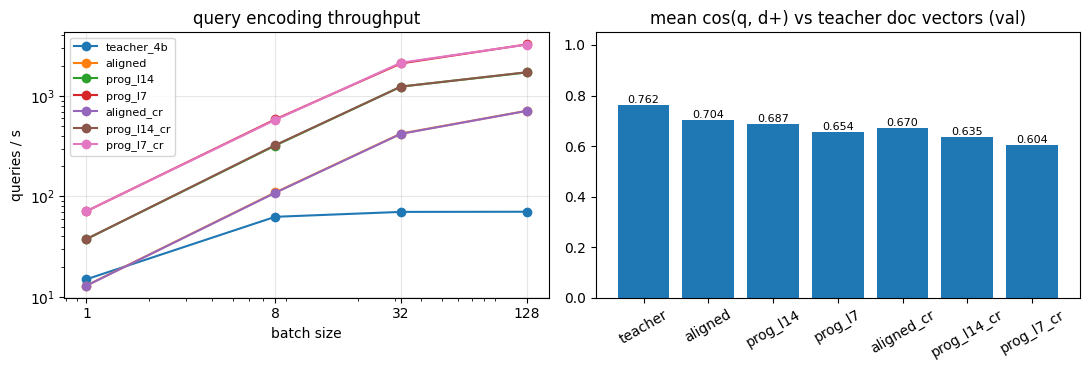

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display
from run_exp import exp_latency

res = exp_latency(LATENCY_MODELS, data, index, RUN_DIR, EVAL["device"], T["dim"], **LATENCY)
print(f"\n{'model':<16}{'params':>9}{'fp16 MB':>9}")
for name, lat in res["latency"].items():
    print(f"{name:<16}{lat['params'] / 1e6:>8.0f}M{lat['params'] * 2 / 1e6:>9.0f}")
for fig in res["figs"]:
    display(fig)
plt.close("all")

## 4 · Ablations (test, from the rows above)
- **alignment**: untrained student (own index) → aligned
- **pruning**: quality lost per cut
- **refinement**: quality recovered by contrastive refinement at each depth

step            from                    to                     ndcg@10      recall@100
prune 28->14    aligned                 prog_l14          0.697->0.641    0.971->0.948
prune 14->7     prog_l14                prog_l7           0.641->0.547    0.948->0.910
refine aligned  aligned                 aligned_cr        0.697->0.728    0.971->0.978
refine prog_l14 prog_l14                prog_l14_cr       0.641->0.670    0.948->0.962
refine prog_l7  prog_l7                 prog_l7_cr        0.547->0.608    0.910->0.942


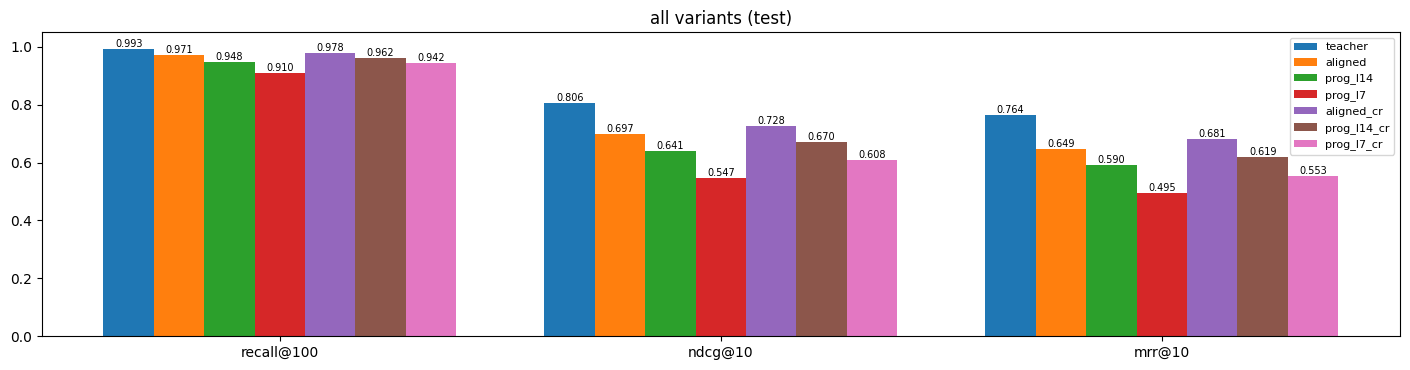

In [7]:
from run_exp import plot_bars, save_fig

STEPS = [("prune 28->14", "aligned", "prog_l14"),
         ("prune 14->7", "prog_l14", "prog_l7"),
         *[(f"refine {n}", n, f"{n}_cr") for n in STUDENTS]]
print(f"{'step':<16}{'from':<24}{'to':<14}" + "".join(f"{k:>16}" for k in ("ndcg@10", "recall@100")))
for step, a, b in STEPS:
    if a in metrics and b in metrics:
        d = {k: (metrics[a]["test"][k], metrics[b]["test"][k]) for k in ("ndcg@10", "recall@100")}
        print(f"{step:<16}{a:<24}{b:<14}" + "".join(f"{x:.3f}->{y:.3f}".rjust(16) for x, y in d.values()))

names = ["teacher", *(n for n in MODELS if n in metrics)]
display(save_fig(plot_bars(metrics, names, title="all variants (test)"), RUN_DIR, "all_variants"))
plt.close("all")